# Nick's action items: augmentation, CFG and fine-tune results

This notebook collects every result for Nick Kern's four action items and the follow-up checks. Each figure is drawn from saved evaluation files, and every cell says where its numbers come from. **Nothing here trains or samples**; it only reads results. Run all cells top to bottom (a few minutes on CPU).

| Item | Question | Section |
|---|---|---|
| 2, 3 | Which augmentations stop the model copying its training maps? | A–F |
| 1 | Classifier-free guidance: how does the guidance scale w change Ω$_m$ recovery and calibration? | G |
| 4 | Fine-tune a trained conditional model with augmentation: does recovery approach a generalized model? | H |
| + | Sampler grid test, P(k) tilt, probe | I |

**Main results in one paragraph**
- **Item 4, the strongest result.** Take the conditional model already trained without augmentation, keep training it for +50k updates with D4 + translation augmentation turned on, and change nothing else. At N = 1,024 it goes from blurry maps with a −0.60 W bias to recovery as good as the N = 32,768 model: bias −0.00 W, 22/32 covered, slope 0.69. Not yet separated from "just training longer" (no matching run without augmentation).
- **Items 2–3.** Translations stop copying at every N tested; flips or rotations alone only move the copying regime to smaller N.
- **Item 1.** Guidance w does not fix the bias; w ≈ 1.5 matches the real-map slope at large N.

**Ground rules**
- One training seed per model, so small differences (2–3 cosmologies in coverage, a few % in P(k)) are within noise.
- Each result was checked by the critic agent and recorded in `experiments/ledger.jsonl`. The verdicts are quoted in each section.
- All samples use DPM-Solver, 50 steps, seed 123, on the scheduler's default ("leading") grid; see section I for why that matters.

**Glossary**
- **N**: number of training maps (2D slices of CAMELS IllustrisTNG HI grids, 128×128). For unconditional runs, 16 slices come from each simulation, so N = 64 is 4 simulations.
- **Generalization score G** (as in the paper, Fig. 1): project maps onto 32 PCA components of the training set; τ = 95th percentile of training-to-training nearest-neighbour similarity; G = fraction of generated maps whose nearest training map is *less* similar than τ. G ≈ 0 means the model reproduces training maps, G ≈ 1 means its maps are novel.
- **Copy fraction**: fraction of generated maps whose best match among training maps, allowing **any rotation, flip and periodic shift**, is above the same kind of threshold. This catches rotated or shifted copies that a plain comparison misses.
- **Memorized**: G < 0.5 or copy fraction ≥ 0.5.
- **P(k) ratio**: power spectrum of generated maps divided by that of real held-out maps (1 = perfect). Bands: large k < 8, mid 8–24, small ≥ 24 (grid units).
- **One-point PDF**: histogram of normalized pixel values.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path('/home/jiamingp/diffusion_models_repo')
for p in (ROOT, ROOT / 'scripts'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import plot_nick_action_items as P          # colours, labels, shared helpers (scripts/plot_nick_action_items.py)
from simdiff_eval.orbit_nn import orbit_max_cosine
from simdiff_eval.aug_wave2_transforms import ShiftOnly, D4Only, FlipOnly
from evaluate_run import UncondData, load_samples
%matplotlib inline
import warnings
warnings.filterwarnings('ignore', message='.*__floordiv__.*'); warnings.filterwarnings('ignore', message='.*not writable.*')

pd.set_option('display.width', 200); pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})

W1 = ROOT / 'results/unet128_aug_sweep/evaluate_run_v1'      # wave 1: noaug (N up to 32768), d4shift, warp, d4equiv
W2 = ROOT / 'results/unet128_aug_wave2/evaluate_run_v1'      # wave 2: fliponly, d4only, shiftonly (+ noaug, d4shift rows)
w1 = pd.read_csv(W1 / 'per_run.csv'); w2 = pd.read_csv(W2 / 'per_run.csv')
curves = np.load(W2 / 'curves.npz', allow_pickle=True)
runs2 = {(r['arm'], r['dataset_size']): r for r in json.loads((ROOT / 'local/unet128_aug_wave2/eval_runs.json').read_text())}
ARMS = P.ARMS                      # ['noaug', 'fliponly', 'd4only', 'shiftonly', 'd4shift']
LAB, COL, MK = P.ARM_LABEL, P.ARM_COLOR, P.ARM_MARKER
print('wave 1 rows', len(w1), '| wave 2 rows', len(w2))

wave 1 rows 28 | wave 2 rows 15


In [2]:
def d4(x, g):
    # D4 element g (same convention as simdiff_eval.orbit_nn / aug_wave2_transforms): rot90 by g % 4, then left-right flip if g >= 4
    y = np.rot90(x, g % 4, axes=(-2, -1))
    return np.flip(y, -1) if g >= 4 else y

def d4_inverse(x, g):
    y = np.flip(x, -1) if g >= 4 else x
    return np.rot90(y, -(g % 4), axes=(-2, -1))

def match(gen_map, train):
    # Best training match of one generated map under rotations, flips and periodic shifts.
    # Returns the training map transformed onto the generated map's frame (the generated map itself is never moved),
    # the cosine similarity (mean-subtracted), and the index of the training map.
    r = orbit_max_cosine(gen_map[None], train, device='cpu', query_batch=1, ref_batch=256)
    g, sy, sx, j = (int(r[k][0]) for k in ('group_element', 'shift_y', 'shift_x', 'ref_index'))
    aligned = d4_inverse(np.roll(train[j], (sy, sx), axis=(0, 1)), g)
    return aligned, float(r['max_cosine'][0]), j

def show(ax, img, ref, title=None, note=None):
    lo, hi = np.percentile(ref, [1, 99.5])
    ax.imshow(img, cmap='magma', vmin=lo, vmax=hi, interpolation='nearest'); ax.set_xticks([]); ax.set_yticks([])
    if title: ax.set_title(title, fontsize=7.5, pad=2)
    if note: ax.text(0.97, 0.04, note, transform=ax.transAxes, ha='right', va='bottom', fontsize=7, color='white')

## A. What each augmentation does

All runs are unconditional UNet-128, trained for 200k updates at batch 32. During training each map is transformed afresh every time it is drawn. Real HI maps are statistically unchanged under these operations, so they add training views without changing the physics.

| Arm | Transform each time a map is drawn | Distinct views per map |
|---|---|---|
| no augmentation | none | 1 |
| flips only | identity or left-right flip, 50/50 | 2 |
| D4 (rotations + flips) | one of the 8 rotations/reflections of the square | 8 |
| translations only | random periodic shift in both directions | 128 × 128 = 16,384 |
| D4 + translations | random D4 element and random shift | 8 × 16,384 |
| D4-equivariant UNet (control) | none; the network is built to be rotation/flip symmetric | (8, by construction) |
| warp (control) | smooth periodic distortion (2 px, 4 waves); changes P(k), so it is a control, not a method | continuous |

Code: `simdiff_eval/aug_wave2_transforms.py` (flips only, D4 only, translations only) and the wave-1 sweep (`local/unet128_aug_sweep/EVAL_PLAN.md`).

**Are shifts safe?** The maps are slices of a periodic simulation box, so a periodic shift should not create an edge. Check below: if the maps are periodic, the pixel jump across the wrapped edge is about the same as between ordinary neighbouring pixels.

training maps: (64, 128, 128); edge jump / interior jump = 0.94 (left-right), 0.75 (top-bottom)


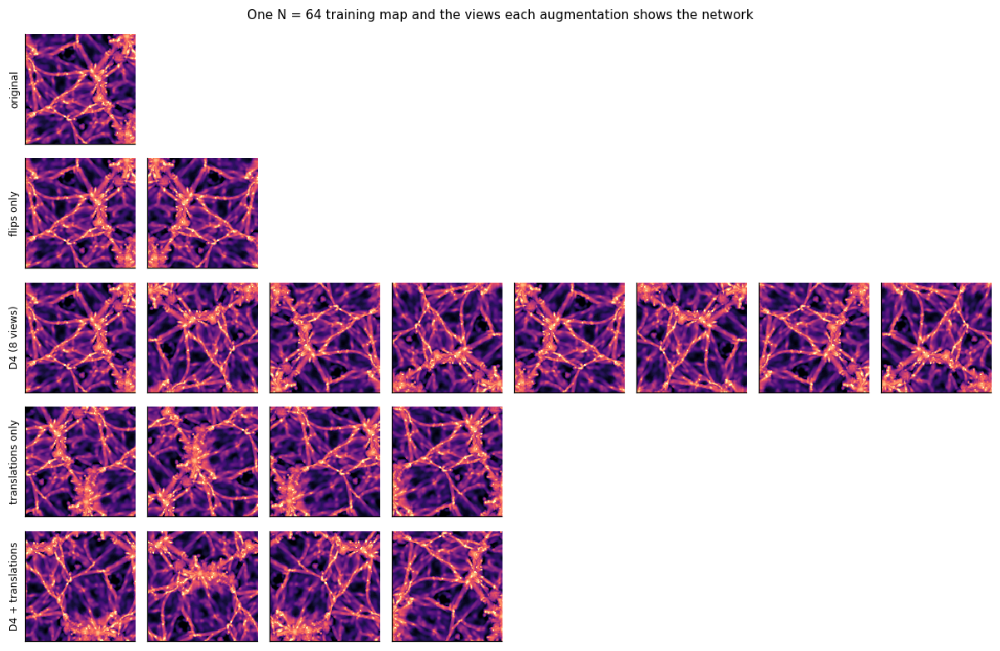

In [3]:
cfg64 = runs2[('noaug', 64)]['config']
data64 = UncondData(ROOT / cfg64, 8, 64)         # the N = 64 training set in its normalized model space
x = data64.train
inner = np.abs(np.diff(x, axis=2)).mean(); wrap = np.abs(x[:, :, 0] - x[:, :, -1]).mean()
inner_y = np.abs(np.diff(x, axis=1)).mean(); wrap_y = np.abs(x[:, 0, :] - x[:, -1, :]).mean()
print(f'training maps: {x.shape}; edge jump / interior jump = {wrap/inner:.2f} (left-right), {wrap_y/inner_y:.2f} (top-bottom)')

m = x[3]
rows = [('original', [m]),
        ('flips only', [d4(m, 0), d4(m, 4)]),
        ('D4 (8 views)', [d4(m, g) for g in range(8)]),
        ('translations only', [ShiftOnly(seed=s)(m) for s in range(4)]),
        ('D4 + translations', [ShiftOnly(seed=s)(d4(m, g)) for s, g in zip(range(4), (1, 3, 5, 6))])]
fig, axes = plt.subplots(len(rows), 8, figsize=(11, 7.2))
for i, (name, views) in enumerate(rows):
    for j in range(8):
        ax = axes[i, j]
        if j < len(views):
            show(ax, views[j], m)
        else:
            ax.axis('off')
    axes[i, 0].set_ylabel(name, fontsize=8)
fig.suptitle('One N = 64 training map and the views each augmentation shows the network', fontsize=10)
plt.tight_layout(); plt.show()

## B. Generalization line: when does each model stop copying?

Same score as the paper's Fig. 1, now for every augmentation arm. Two versions:
- **Left, plain G (as in the paper):** compares each generated map with training maps as they are. A generated map that is a *rotated* copy of a training map looks novel here.
- **Right, G with rotations and flips allowed:** the nearest-neighbour search may rotate or flip the generated map. For augmented models this is the fair version.

Bottom row: the copy fraction (rotations, flips **and** shifts allowed), the most direct measure of copying.

**Why left and right differ.** Both find each generated map's most similar training map. Left compares pixels exactly as they are. Right first tries the generated map rotated by 90°, 180°, 270° and mirrored (8 versions) and keeps the best match. A model trained with flips or rotations can output a *rotated copy*: pixel by pixel it does not line up, so the left panel calls it novel, while the right panel rotates it back and sees the copy. Example, D4 only at N = 64: left G = 0.89 (novel), right G = 0.07 (copying).

Sources: `results/unet128_aug_sweep/evaluate_run_v1/per_run.csv` (wave 1) and `results/unet128_aug_wave2/evaluate_run_v1/per_run.csv` (wave 2). Wave 2 (flips only, D4 only, translations only) was trained at N = 64, 128 and 256 only.

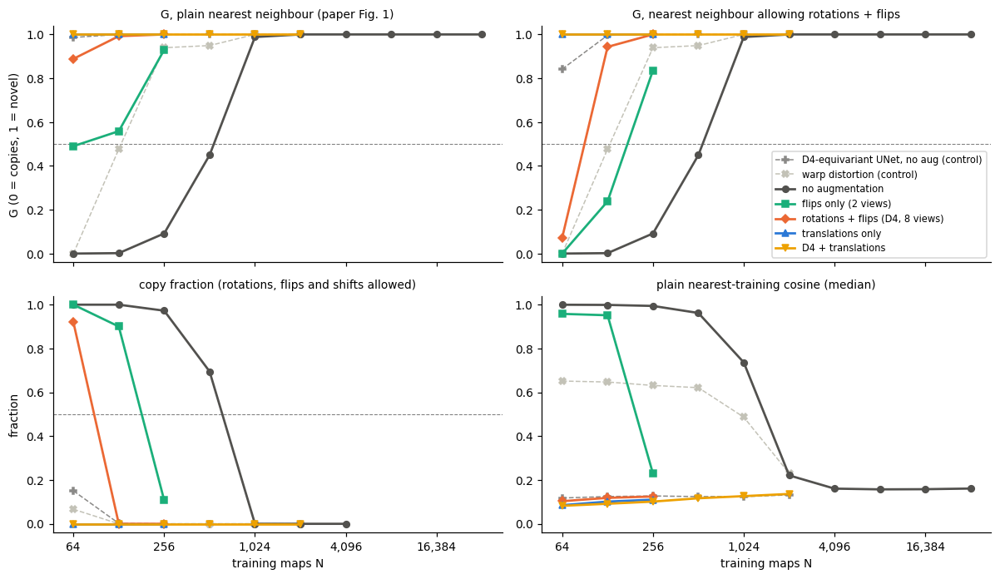

Copy fraction is not computed for N > 4,096 (search too large); those no-augmentation runs have G = 1.


In [4]:
allarms = pd.concat([w1, w2[w2.arm.isin(['fliponly', 'd4only', 'shiftonly'])]], ignore_index=True)
extra = {'d4equiv': ('D4-equivariant UNet, no aug (control)', '#8a8987', 'P'), 'warp': ('warp distortion (control)', '#c3c2b7', 'X')}
style = lambda a: extra[a] if a in extra else (LAB[a], COL[a], MK[a])
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True)
for ax, key, title in ((axes[0, 0], 'G_none', 'G, plain nearest neighbour (paper Fig. 1)'),
                       (axes[0, 1], 'G_d4', 'G, nearest neighbour allowing rotations + flips'),
                       (axes[1, 0], 'orbit_copy_fraction', 'copy fraction (rotations, flips and shifts allowed)'),
                       (axes[1, 1], 'nearest_train_cosine_median', 'plain nearest-training cosine (median)')):
    if key != 'nearest_train_cosine_median':
        ax.axhline(0.5, color='0.5', lw=0.7, ls='--')
    for arm in list(extra) + ARMS:
        g = allarms[allarms.arm == arm].sort_values('dataset_size').dropna(subset=[key])
        lab, c, mk = style(arm)
        ax.plot(g.dataset_size, g[key], color=c, marker=mk, ms=5, lw=1.0 if arm in extra else 1.8,
                ls='--' if arm in extra else '-', label=lab)
    ax.set_xscale('log', base=2); ax.set_ylim(-0.04, 1.04); ax.set_title(title, fontsize=9)
    ax.set_xticks([64, 256, 1024, 4096, 16384]); ax.set_xticklabels(['64', '256', '1,024', '4,096', '16,384'])
for ax in axes[1]: ax.set_xlabel('training maps N')
axes[0, 0].set_ylabel('G (0 = copies, 1 = novel)'); axes[1, 0].set_ylabel('fraction')
axes[0, 1].legend(fontsize=7.5, loc='lower right')
plt.tight_layout(); plt.show()
print('Copy fraction is not computed for N > 4,096 (search too large); those no-augmentation runs have G = 1.')

The same scores, **one panel per augmentation** so nothing overlaps. Grey: no augmentation (in every panel). Solid line: G allowing rotations + flips; dashed open circles: plain G as in the paper. Numbers are the solid-line values.

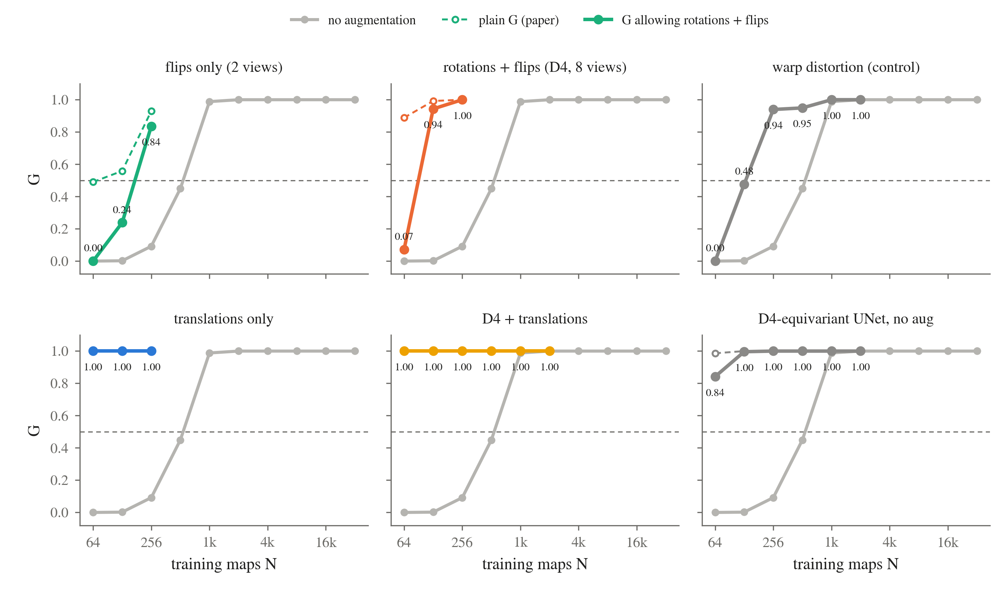

Figure made by scripts/plot_nick_action_items.py from the same per_run.csv files as above.


In [5]:
NK = ROOT / 'results/nick_action_items_20261014_134248'
display(Image(str(NK / 'w2_generalization_panels.png'), width=1000))
print('Figure made by scripts/plot_nick_action_items.py from the same per_run.csv files as above.')

In [6]:
tab = allarms.pivot_table(index='arm', columns='dataset_size', values='G_d4').reindex(['noaug', 'fliponly', 'd4only', 'warp', 'd4equiv', 'shiftonly', 'd4shift'])
print('G with rotations + flips allowed (rows: arm, columns: N)')
display(tab.round(2))

G with rotations + flips allowed (rows: arm, columns: N)


dataset_size,64,128,256,512,1024,2048,4096,8192,16384,32768
arm,,,,,,,,,,
noaug,0.00,0.00,0.09,0.45,0.99,1.0,1.0,1.0,1.0,1.0
fliponly,0.00,0.24,0.84,NaN,NaN,NaN,NaN,NaN,NaN,NaN
d4only,0.07,0.94,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
warp,0.00,0.48,0.94,0.95,1.00,1.0,NaN,NaN,NaN,NaN
d4equiv,0.84,1.00,1.00,1.00,1.00,1.0,NaN,NaN,NaN,NaN
shiftonly,1.00,1.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
d4shift,1.00,1.00,1.00,1.00,1.00,1.0,NaN,NaN,NaN,NaN


**Reading the generalization line**
- **No augmentation** crosses G = 0.5 between N = 512 (0.45) and N = 1,024 (0.99). This is the transition in the paper.
- **Fewer views bring the transition back down to smaller N (item 2).**
  - D4 only (8 views) copies at N = 64 (copy fraction 0.92) and is novel from N = 128.
  - Flips only (2 views) copies at N = 64 and 128 (copy fraction 1.00, 0.90) and is mostly novel at 256 (0.11).
  - The ordering none ≥ flips ≥ D4 > translations holds at every N.
- **Counting views only roughly predicts the transition.** Dividing the no-augmentation transition (~512–1,024) by the number of views predicts D4 at ~64–128, as seen. For flips only it predicts ~256–512, but flips only stops copying one factor of 2 earlier. Its N = 256 samples are still close to training maps (median match 0.91 vs threshold 0.957).
- **Translations, alone or with D4, never copy at any N tested (item 3).**
- **Warp (control) still copies at small N** (G = 0.00 at N = 64, 0.48 at 128), novel from 256: smooth 2-pixel distortions do not stop copying. Its copy fraction at N = 64 is only 0.07 because the copy test needs an exact rotation or shift match; warped copies slip past it, but G catches them.
- **The plain G of the paper misses rotated copies.** It gives D4-only N = 64 a score of 0.89 (novel) and flips-only N = 64 0.49, although both copy. Use the right-hand panel for augmented models.

Ledger: `unet128_aug_wave2` and `unet128_aug_wave2_eval`, verdict **mixed**. The prediction that flips only stays memorized at N = 256 was wrong.

## C. Generated maps next to their closest training map

Each row is one augmentation; each **pair** of panels is one generated map (left) next to its closest training map (right). The model made 512 maps; they are sorted by how similar each is to its closest training map, and three are shown: the **10th percentile** (one of the most novel maps), the **50th** (a typical map) and the **90th** (one of the most copy-like maps). This shows the spread, not one hand-picked example. "#439" in the corner is the sample number out of 512. Next to each is its best match among the training maps, found by trying every rotation, flip and periodic shift.

**The generated map is shown exactly as sampled.** The training map is the one that gets rotated, flipped and shifted into the generated map's frame, so you can compare pixel by pixel. The number is the cosine similarity of the pair: 1 is an exact copy, ~0.1–0.3 is typical of unrelated real maps.

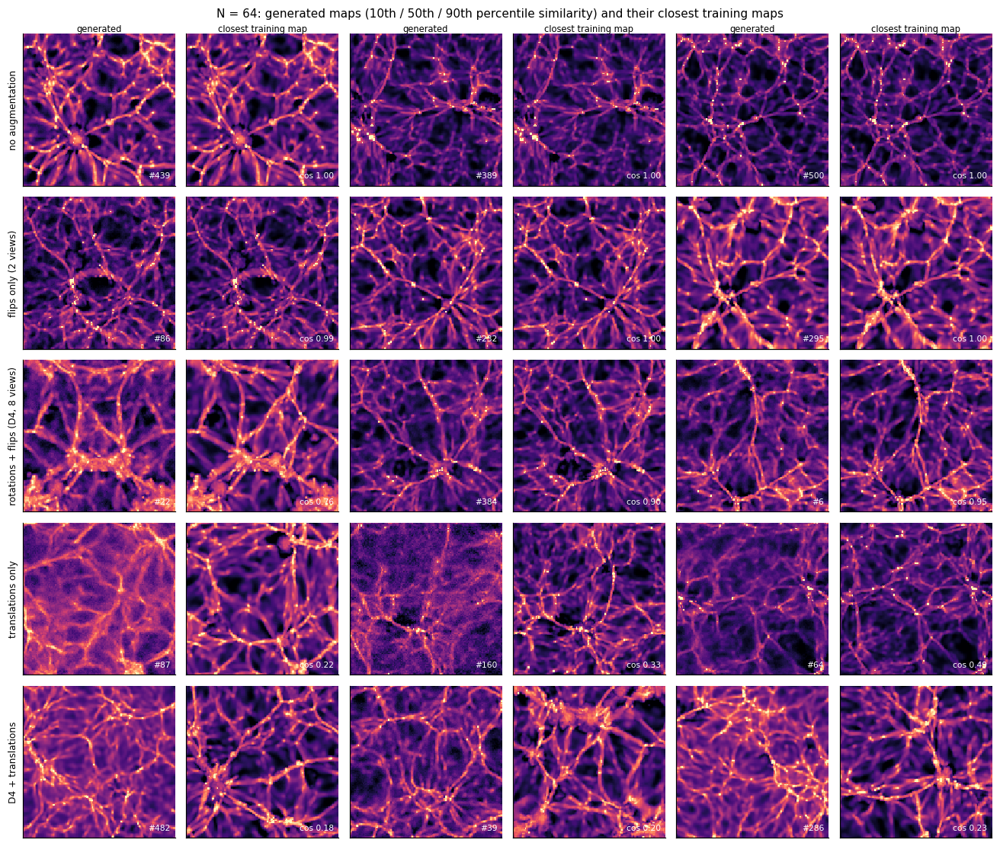

In [7]:
_DATA = {}
def training_maps(config):
    # each run's own training set (same simulations for every arm at a given N; loaded per config to be safe)
    if config not in _DATA:
        _DATA[config] = UncondData(ROOT / config, 8, 64).train
    return _DATA[config]

def gallery(N, picks=(0.1, 0.5, 0.9)):
    fig, axes = plt.subplots(len(ARMS), 2 * len(picks), figsize=(12, 2.05 * len(ARMS)))
    rows = []
    for i, arm in enumerate(ARMS):
        r = runs2[(arm, N)]
        train = training_maps(r['config'])
        gen = load_samples(ROOT / r['sample_path'].format(seed=123))
        nn = np.load(W2 / f"{r['run_name']}_per_sample.npz")['orbit_nn']
        order = np.argsort(nn)
        for j, q in enumerate(picks):
            idx = int(order[int(q * (len(order) - 1))])
            ref, cos, ti = match(gen[idx], train)
            show(axes[i, 2 * j], gen[idx], ref, title='generated' if i == 0 else None, note=f'#{idx}')
            show(axes[i, 2 * j + 1], ref, ref, title='closest training map' if i == 0 else None, note=f'cos {cos:.2f}')
            rows.append(dict(arm=arm, N=N, percentile=q, sample=idx, train_index=ti, cosine=cos))
        axes[i, 0].set_ylabel(LAB[arm], fontsize=8)
    fig.suptitle(f'N = {N}: generated maps (10th / 50th / 90th percentile similarity) and their closest training maps', fontsize=10)
    plt.tight_layout(); plt.show()
    return pd.DataFrame(rows)

g64 = gallery(64)

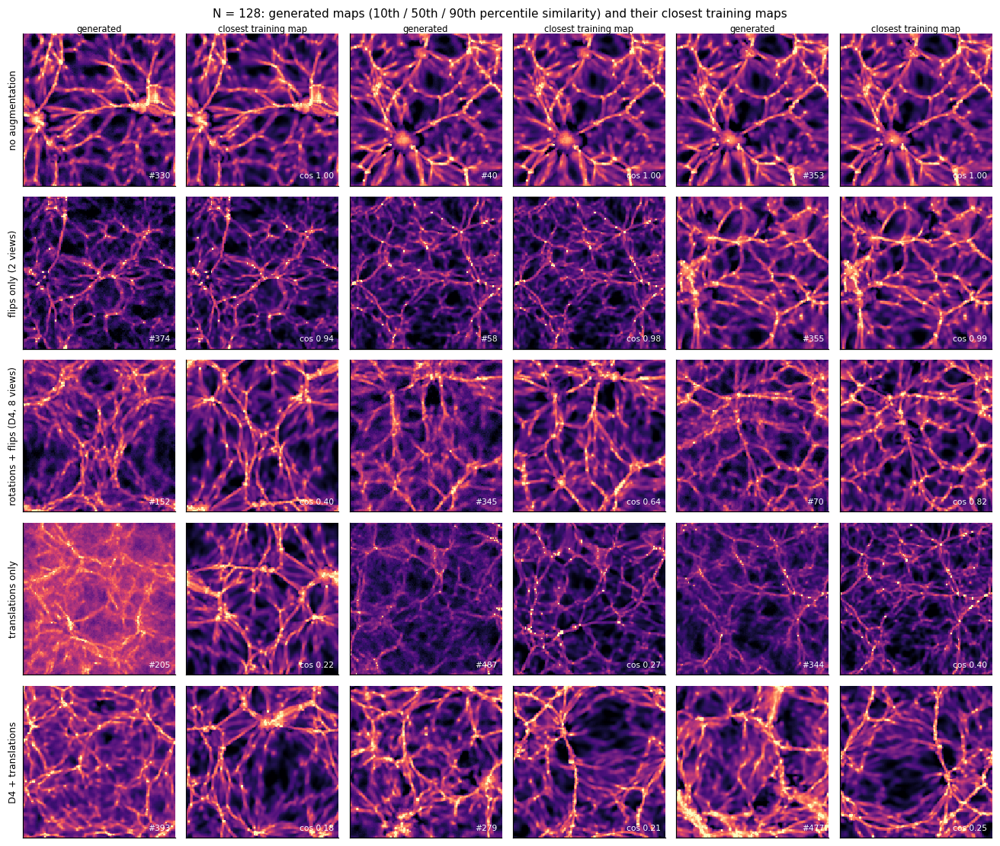

In [8]:
g128 = gallery(128)

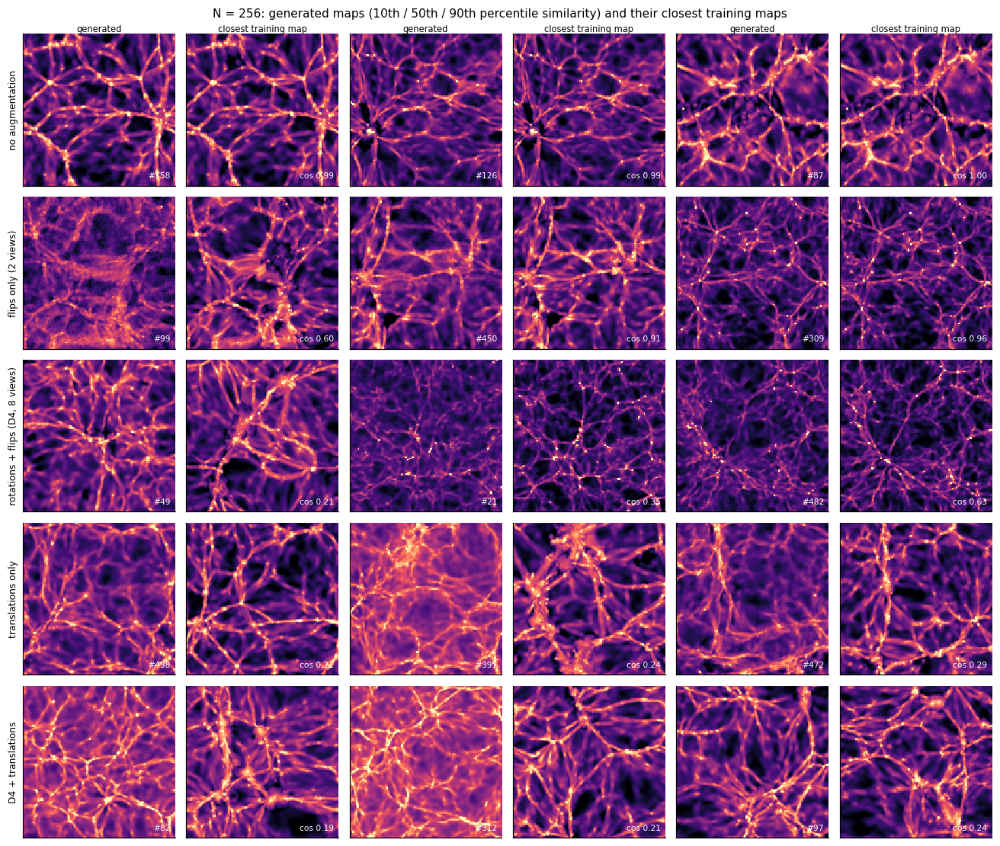

In [9]:
g256 = gallery(256)

**What to look for**
- No augmentation: the generated map *is* a training map (cos ≈ 1.00) at every N shown.
- Flips only at N = 64–128, D4 only at N = 64: the match is a flipped or rotated training map. The cosine is high only because the search allowed that transform.
- Translations, alone or with D4: the closest training map is clearly different (cos ≈ 0.1–0.35), so these are new maps.
- An earlier gallery on the results page shifted the *generated* map instead. That moved its edges into the panel and showed straight "seams". Translation-augmented models make maps whose opposite edges do not join smoothly; the training maps do join (edge check in section A). Showing generated maps unmoved, as here, avoids that artifact.

In [10]:
def wrap_ratio(maps):
    inner = np.abs(np.diff(maps, axis=2)).mean(); wrap = np.abs(maps[:, :, 0] - maps[:, :, -1]).mean()
    return wrap / inner
rows = []
for (arm, N), r in sorted(runs2.items(), key=lambda t: (t[0][1], ARMS.index(t[0][0]))):
    rows.append(dict(N=N, arm=arm, edge_jump_ratio=wrap_ratio(load_samples(ROOT / r['sample_path'].format(seed=123))[:256])))
print('Edge jump / interior jump for generated maps (training maps: see section A; ~1 means periodic)')
display(pd.DataFrame(rows).pivot(index='arm', columns='N', values='edge_jump_ratio').reindex(ARMS).round(2))

Edge jump / interior jump for generated maps (training maps: see section A; ~1 means periodic)


N,64,128,256
arm,,,
noaug,0.93,1.00,1.13
fliponly,1.06,1.19,1.54
d4only,1.37,1.85,2.37
shiftonly,3.18,3.92,4.03
d4shift,3.74,3.37,3.19


## D. One-point statistics

The one-point PDF is the histogram of pixel values in the model's normalized space (log, centre and max, then tanh). The grey fill is real held-out maps. The table compares summary statistics of the generated maps with real held-out maps of the same N setup. `one_point_l1` is the L1 distance between the generated and held-out PDFs; `ref_one_point_l1` is the same distance between training and held-out real maps, i.e. the level expected from real data alone.

Source: `results/unet128_aug_wave2/evaluate_run_v1/curves.npz` and `per_run.csv`.

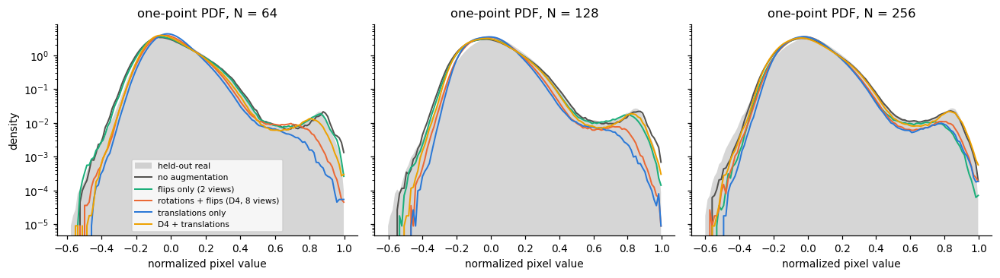

gen_mean  ref_heldout_mean  gen_std  ref_heldout_std  gen_skew  ref_heldout_skew  gen_excess_kurtosis  ref_heldout_excess_kurtosis  gen_q01  ref_heldout_q01  gen_q99  \
dataset_size arm                                                                                                                                                                                
64           noaug        -0.001             0.016    0.144            0.137     1.169             1.141                3.581                        3.806   -0.255           -0.234    0.398   
             fliponly      0.000             0.016    0.139            0.137     1.206             1.141                3.838                        3.806   -0.247           -0.234    0.388   
             d4only        0.003             0.016    0.119            0.137     1.029             1.141                3.079                        3.806   -0.219           -0.234    0.338   
             shiftonly     0.006             0.016    0.107            0.137     0.870             1.141                2.548                        3.806   -0.204           -0.234    0.311   
             d4shift       0.000             0.016    0.127            0.137     1.248             1.141                4.068                        3.806   -0.220           -0.234    0.358   
128          noaug         0.001             0.031    0.149            0.140     1.065             1.076                3.369                        4.055   -0.269           -0.240    0.408   
             fliponly      0.001             0.031    0.141            0.140     0.988             1.076                3.097                        4.055   -0.259           -0.240    0.383   
             d4only        0.003             0.031    0.122            0.140     0.764             1.076                2.200                        4.055   -0.231           -0.240    0.327   
             shiftonly    -0.001             0.031    0.117            0.140     0.733             1.076                1.918                        4.055   -0.221           -0.240    0.311   
             d4shift      -0.000             0.031    0.140            0.140     1.064             1.076                3.462                        4.055   -0.250           -0.240    0.375   
256          noaug         0.001             0.021    0.145            0.143     1.100             1.014                3.752                        3.965   -0.268           -0.263    0.399   
             fliponly      0.000             0.021    0.127            0.143     0.842             1.014                2.826                        3.965   -0.250           -0.263    0.342   
             d4only        0.001             0.021    0.127            0.143     0.918             1.014                3.311                        3.965   -0.244           -0.263    0.341   
             shiftonly    -0.000             0.021    0.123            0.143     0.917             1.014                3.090                        3.965   -0.232           -0.263    0.329   
             d4shift      -0.004             0.021    0.142            0.143     1.151             1.014                4.013                        3.965   -0.262           -0.263    0.381   

                        ref_heldout_q99  one_point_l1  ref_one_point_l1  
dataset_size arm                                                         
64           noaug                0.393         0.152             0.145  
             fliponly             0.393         0.134             0.145  
             d4only               0.393         0.124             0.145  
             shiftonly            0.393         0.209             0.145  
             d4shift              0.393         0.141             0.145  
128          noaug                0.415         0.231             0.239  
             fliponly             0.415         0.207             0.239  
             d4only               0.415         0.175             0.239  
  

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, N in zip(axes, (64, 128, 256)):
    e = curves[f'N{N}_reference__pdf_edges']; c = 0.5 * (e[1:] + e[:-1])
    ax.fill_between(c, curves[f'N{N}_reference__pdf_val'], color='0.6', alpha=0.4, lw=0, label='held-out real')
    for arm in ARMS:
        run = w2[(w2.arm == arm) & (w2.dataset_size == N)].run_name.iloc[0]
        ax.plot(c, curves[f'{run}__pdf_gen'], color=COL[arm], lw=1.3, label=LAB[arm])
    ax.set_yscale('log'); ax.set_title(f'one-point PDF, N = {N}'); ax.set_xlabel('normalized pixel value')
axes[0].set_ylabel('density'); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

cols = ['dataset_size', 'arm', 'gen_mean', 'ref_heldout_mean', 'gen_std', 'ref_heldout_std', 'gen_skew', 'ref_heldout_skew',
        'gen_excess_kurtosis', 'ref_heldout_excess_kurtosis', 'gen_q01', 'ref_heldout_q01', 'gen_q99', 'ref_heldout_q99',
        'one_point_l1', 'ref_one_point_l1']
t = w2[cols].copy(); t['o'] = t.arm.map({a: i for i, a in enumerate(ARMS)})
display(t.sort_values(['dataset_size', 'o']).drop(columns='o').set_index(['dataset_size', 'arm']).round(3))

## E. Power spectrum

P$_{gen}$/P$_{real}$ per k for each arm, against real held-out maps of the same setup; 1 is perfect. The grey line is real training maps against real held-out maps, i.e. the scatter expected from real data. **A memorized model simply reproduces the training maps' P(k)**, so a ratio near 1 for a copying model says nothing about learning; compare P(k) only between models that do not copy.

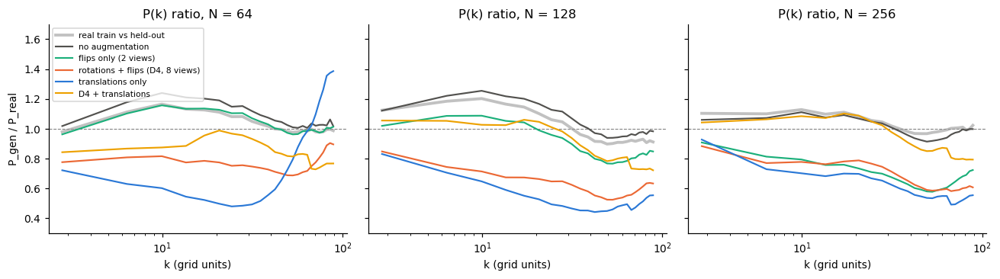

memorized  pk_large  pk_mid  pk_small  ref_pk_large  ref_pk_mid  ref_pk_small
dataset_size arm                                                                                     
64           noaug           True      1.09    1.21      1.06          1.04        1.13          1.01
             fliponly        True      1.03    1.14      1.02          1.04        1.13          1.01
             d4only          True      0.79    0.79      0.72          1.04        1.13          1.01
             shiftonly      False      0.67    0.54      0.65          1.04        1.13          1.01
             d4shift        False      0.85    0.92      0.87          1.04        1.13          1.01
128          noaug           True      1.17    1.21      1.00          1.15        1.15          0.95
             fliponly        True      1.05    1.04      0.82          1.15        1.15          0.95
             d4only         False      0.79    0.68      0.57          1.15        1.15          0.95
             shiftonly      False      0.76    0.58      0.47          1.15        1.15          0.95
             d4shift        False      1.05    1.04      0.85          1.15        1.15          0.95
256          noaug           True      1.07    1.09      0.96          1.10        1.10          0.99
             fliponly       False      0.86    0.76      0.62          1.10        1.10          0.99
             d4only         False      0.82    0.78      0.64          1.10        1.10          0.99
             shiftonly      False      0.82    0.69      0.58          1.10        1.10          0.99
             d4shift        False      1.05    1.09      0.91          1.10        1.10          0.99

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, N in zip(axes, (64, 128, 256)):
    kc = curves['kc']
    ax.axhline(1, color='0.5', lw=0.7, ls='--')
    ax.plot(kc, curves[f'N{N}_reference__pk_ratio'], color='0.6', lw=2.5, alpha=0.6, label='real train vs held-out')
    for arm in ARMS:
        run = w2[(w2.arm == arm) & (w2.dataset_size == N)].run_name.iloc[0]
        ax.plot(kc, curves[f'{run}__pk_ratio'], color=COL[arm], lw=1.4, label=LAB[arm])
    ax.set(xscale='log', ylim=(0.3, 1.7), title=f'P(k) ratio, N = {N}', xlabel='k (grid units)')
axes[0].set_ylabel('P_gen / P_real'); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

b = w2[['dataset_size', 'arm', 'memorized', 'pk_large', 'pk_mid', 'pk_small', 'ref_pk_large', 'ref_pk_mid', 'ref_pk_small']].copy()
b['o'] = b.arm.map({a: i for i, a in enumerate(ARMS)})
display(b.sort_values(['dataset_size', 'o']).drop(columns='o').set_index(['dataset_size', 'arm']).round(2))

## F. Summary for items 2 and 3

- **Item 2: removing non-translation views brings copying back.** D4 only copies at N = 64; flips only copies up to N = 128; no augmentation copies up to N ≈ 512. The transition moves to smaller N as views are added, roughly but not exactly as the number of views predicts.
- **Item 3: translations alone remove copying at every N tested (64–256), but the maps are statistically worse.** Translations only has the lowest P(k) of the non-copying arms in 8 of 9 band × N cells (large 0.67–0.82, mid 0.54–0.69, small 0.47–0.65). D4 + translations also never copies and has the best P(k) (large and mid 0.85–1.09).
- **Practical choice:** D4 + translations.
- **Limits:** unconditional models only, one seed, wave-2 arms only at N ≤ 256. Ledger verdict: mixed.

## G. Item 1: classifier-free guidance (conditional models)

Each conditional model (label = Ω$_m$, σ$_8$) is trained once with 10% of labels replaced by a null label. At sampling, **w** mixes the conditional and unconditional predictions: v = v$_{null}$ + w (v$_{cond}$ − v$_{null}$). w = 0 ignores the cosmology, w = 1 is plain conditioning, w > 1 pushes harder toward it. Ω$_m$ is read from each generated map by the frozen VGG probe and compared with the requested value at 32 held-out cosmologies (64 draws each).

- **Covered 68%**: the number of cosmologies whose central 68% interval of recovered values contains the truth. Real maps: 27/32.
- **Bias**: median over cosmologies of recovered − true, in units of W = 0.0931 (the probe's interval width on real maps).
- **1-to-1 slope**: of recovered vs true. Real maps: 0.80, because the probe itself pulls answers slightly toward the middle.

Figures: `results/cfg_results_by_w_20261012_002216/` (`scripts/plot_cfg_results_by_w.py`).

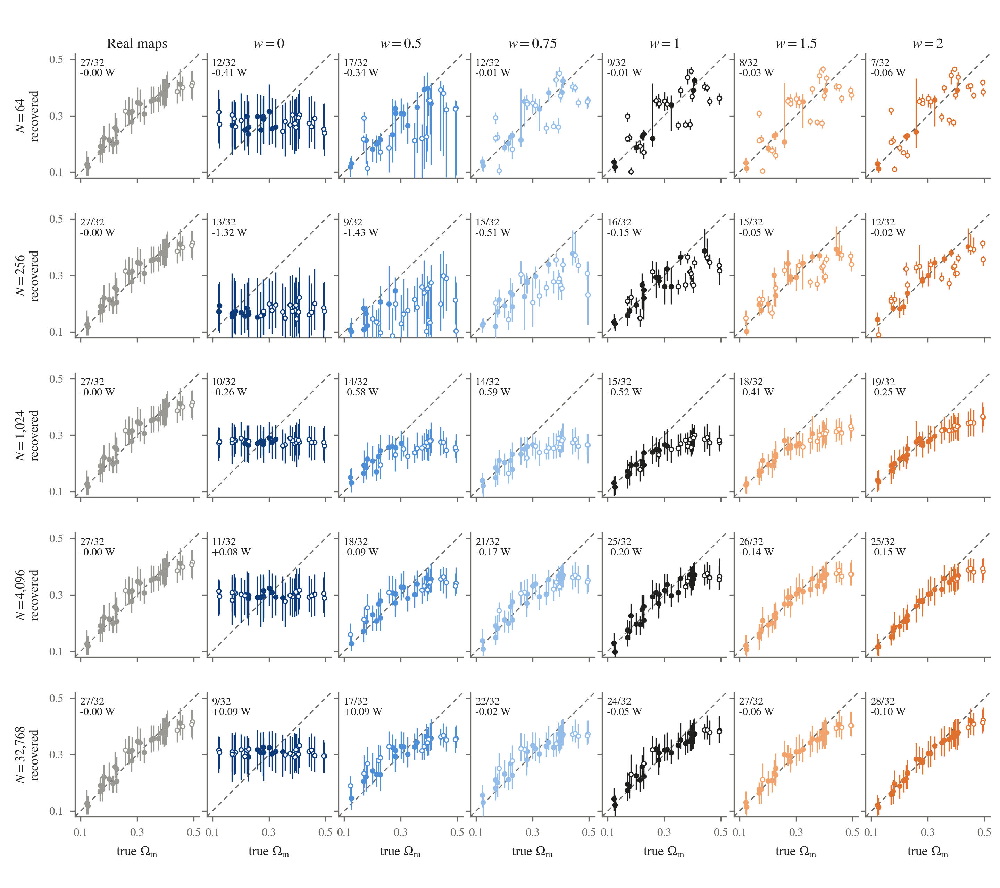

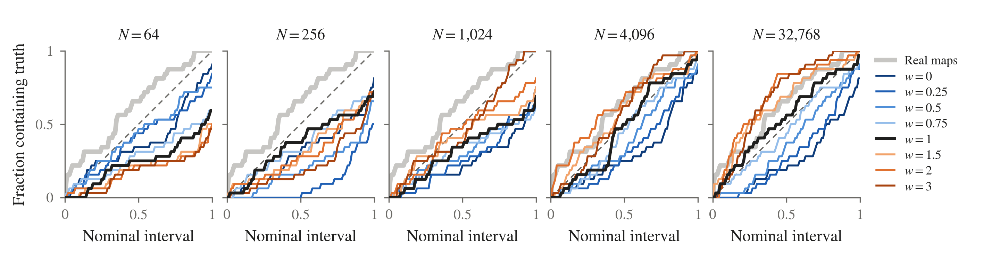

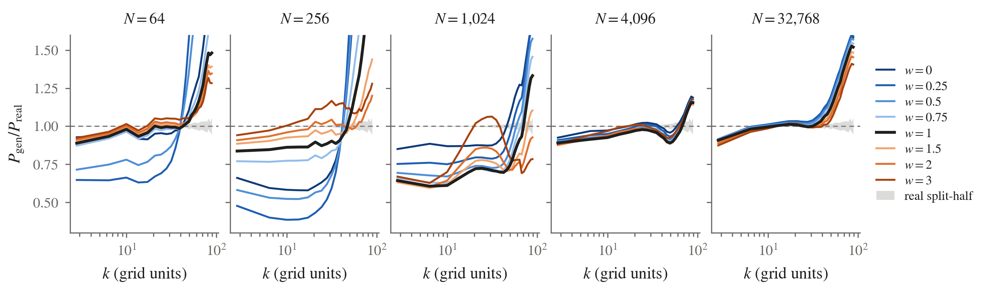

1-to-1 slope (real 0.80)


N,64,256,1024,4096,32768
w,,,,,
0.00,-0.03,0.04,-0.01,-0.01,-0.01
0.25,0.05,0.06,0.18,0.32,0.29
0.50,0.59,0.28,0.29,0.52,0.49
0.75,0.68,0.51,0.36,0.63,0.60
1.00,0.70,0.54,0.42,0.69,0.68
1.50,0.75,0.59,0.51,0.74,0.78
2.00,0.78,0.64,0.58,0.79,0.84
3.00,0.80,0.69,0.66,0.87,0.92


covered 68% of 32 (real 27)


N,64,256,1024,4096,32768
w,,,,,
0.00,12,13,10,11,9
0.25,17,3,11,15,14
0.50,17,9,14,18,17
0.75,12,15,14,21,22
1.00,9,16,15,25,24
1.50,8,15,18,26,27
2.00,7,12,19,25,28
3.00,8,7,21,27,29


bias / W


N,64,256,1024,4096,32768
w,,,,,
0.00,-0.41,-1.32,-0.26,0.08,0.09
0.25,-0.78,-2.04,-0.48,0.01,0.17
0.50,-0.34,-1.43,-0.58,-0.09,0.09
0.75,-0.01,-0.51,-0.59,-0.17,-0.02
1.00,-0.01,-0.15,-0.52,-0.20,-0.05
1.50,-0.03,-0.05,-0.41,-0.14,-0.06
2.00,-0.06,-0.02,-0.25,-0.15,-0.10
3.00,-0.01,-0.13,0.05,-0.30,-0.16


width68 (real 0.093)


N,64,256,1024,4096,32768
w,,,,,
0.00,0.17,0.19,0.12,0.15,0.14
0.25,0.15,0.14,0.09,0.11,0.11
0.50,0.14,0.17,0.09,0.09,0.10
0.75,0.04,0.07,0.08,0.08,0.09
1.00,0.04,0.06,0.08,0.08,0.09
1.50,0.03,0.05,0.08,0.08,0.09
2.00,0.03,0.04,0.08,0.08,0.09
3.00,0.02,0.04,0.09,0.09,0.09


In [13]:
CFG = ROOT / 'results/cfg_results_by_w_20261012_002216'
display(Image(str(CFG / 'omega_m_recovery_grid.png'), width=1000))
display(Image(str(CFG / 'coverage_by_w.png'), width=1000))
display(Image(str(CFG / 'pk_ratio_by_w.png'), width=1000))
s = pd.read_csv(CFG / 'summary_by_N_w.csv')
for key, name in (('slope', '1-to-1 slope (real 0.80)'), ('covered68', 'covered 68% of 32 (real 27)'), ('bias_over_W', 'bias / W'), ('width68', 'width68 (real 0.093)')):
    print(name); display(s.pivot(index='w', columns='N', values=key).round(2))

**Reading item 1** (ledger `nf_cond_omsigc_cfg`, verdict **unsupported**: the pre-registered hypothesis that w < 1 reduces the bias is refuted)
- Going from w = 1 to w = 0.5 *raises* |bias| at N = 64, 256 and 1,024, and flattens the slope.
- **Slope rises with w at every N.** At N ≥ 4,096, w ≈ 1.5 matches the real-map slope (0.74–0.78 vs 0.80); w = 2 overshoots.
- **At small N, w < 1 widens the intervals.** At N = 64 the model copies, and w = 0.5 widens the intervals (0.139 vs 0.038), so coverage rises (17 vs 9/32). The per-cosmology error does not improve.
- **N = 1,024 is weak at every w**, and N = 256 is poor below w = 1 (its unconditional branch is undertrained).
- **The criterion for choosing w is not fixed yet.** "Best w rises with N" is true for some metrics only.

## H. Item 4: fine-tuning trained conditional models with D4 + translations

**What was done, in one sentence:** take the conditional model already trained for 200k updates without augmentation, and simply keep training it (same data, labels, optimizer and learning rate) with D4 + translation augmentation switched on; checkpoints after +25k and +50k updates (+100k at N = 256) are sampled and scored exactly like the original.

The trained (Ω$_m$, σ$_8$) conditional models, without CFG, continue training with D4 + periodic-shift augmentation. Labels, optimizer and learning-rate schedule are unchanged. N = 256 was a copying model; N = 1,024 was in the transition and had lost half its large-scale power; N = 4,096 already generalized and checks for damage. Reference: the generalized N = 32,768 model has bias +0.05 W, 21/32 covered, slope 0.73.

Sources: `results/nf_cond_omsigc_n256_aug_finetune/evaluate_run_v1/`, `results/nf_cond_omsigc_n1024_n4096_aug_finetune/{evaluate_run_plus0,evaluate_run_v1}/`. Summary and figures: `results/nick_action_items_20261014_134248/`.

covered68  bias_over_W  width68  slope  median_abs_error  pk_large  pk_mid  pk_small  nearest_train_cosine_median  pix_std_ratio_median
N    step                                                                                                                                         
256  0            13       -0.369    0.052  0.605             0.038     0.820   0.818     0.945                        0.951                 0.946
     25           19       -0.183    0.086  0.586             0.038     0.919   1.005     0.989                        0.123                 0.994
     50           17       -0.255    0.083  0.625             0.030     0.881   0.930     1.034                        0.126                 0.967
     100          19       -0.113    0.084  0.652             0.033     0.853   0.953     1.013                        0.123                 0.966
1024 0            10       -0.599    0.080  0.416             0.056     0.507   0.531     0.659                        0.194                 0.759
     25           20       -0.217    0.087  0.656             0.027     0.975   0.954     0.979                        0.147                 0.998
     50           22       -0.003    0.085  0.695             0.024     0.916   0.990     1.047                        0.143                 0.988
4096 0            24       -0.160    0.084  0.713             0.026     0.896   0.942     0.906                        0.164                 0.962
     25           21       -0.032    0.082  0.719             0.030     0.932   0.989     0.949                        0.160                 0.988
     50           23       -0.106    0.087  0.707             0.025     1.030   0.995     0.990                        0.163                 1.004

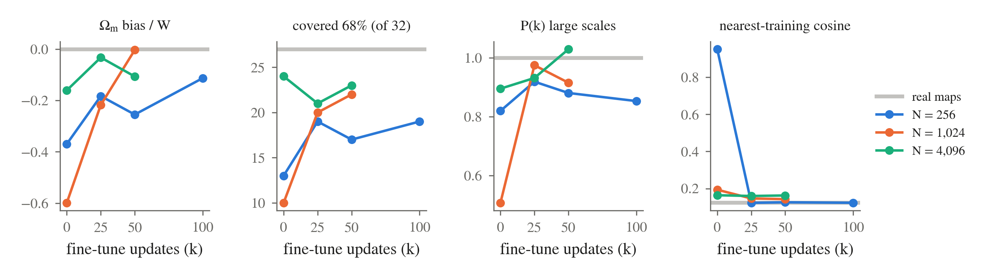

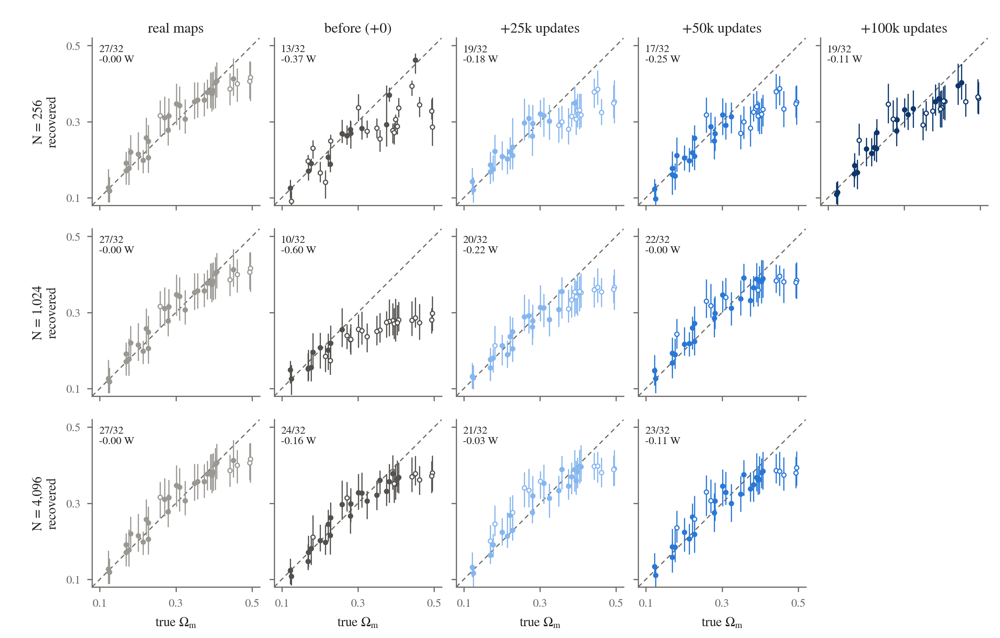

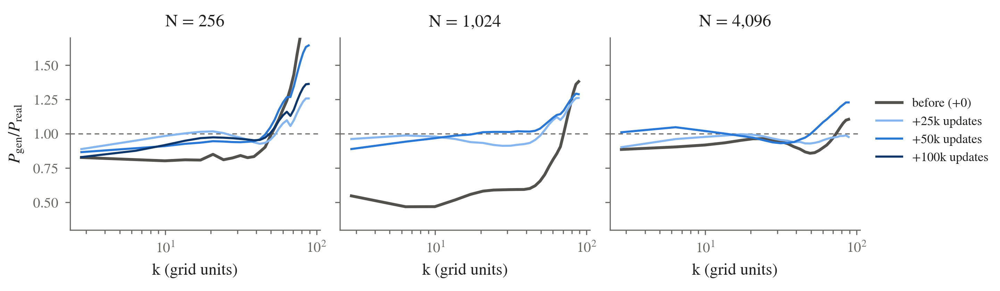

In [14]:
NK = ROOT / 'results/nick_action_items_20261014_134248'
ft = pd.read_csv(NK / 'finetune_summary.csv')
display(ft.drop(columns='run').set_index(['N', 'step']).round(3))
display(Image(str(NK / 'ft_metrics_vs_updates.png'), width=1000))
display(Image(str(NK / 'ft_recovery_grid.png'), width=1000))
display(Image(str(NK / 'ft_pk.png'), width=1000))

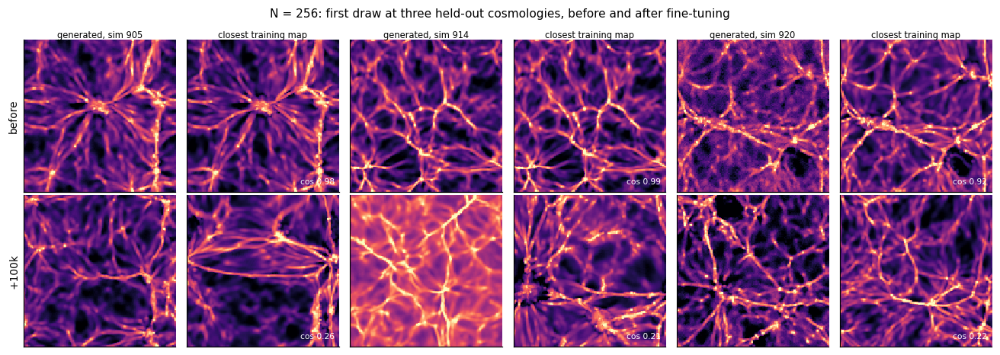

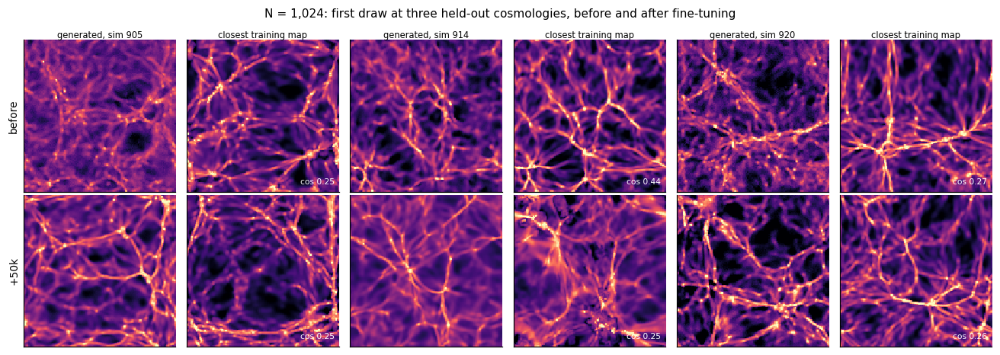

In [15]:
# Generated maps before and after fine-tuning, next to their closest training map (generated map unmoved).
from simdiff_eval.conditional_unet_diagnostics import normalize_raw_hi
norm = dict(np.load(ROOT / 'results/nf_conditional_bias_probe/encoder/vgg_mlp_encoder.npz', allow_pickle=True)['normalization'].item())
PREP = Path('/scratch/huterer_root/huterer0/jiamingp/saved_runs/nf_conditional_omsig_continuous_200k/prepared_data')
pairs = [(256, 'd2p08', 'nf_cond_omsigc_n256_aug_finetune', 'ft100k', '+100k'), (1024, 'd2p10', 'nf_cond_omsigc_n1024_n4096_aug_finetune', 'ft050k', '+50k')]
for N, d, folder, tag, lab in pairs:
    raw = np.load(PREP / f'nf_cond_omsigc_hi_u128_{d}_n{N}_fresh200k_train_images.npy', mmap_mode='r')
    train = np.asarray(normalize_raw_hi(raw[:, 0], norm), dtype=np.float32).reshape(len(raw), 128, 128)
    files = {'before': ROOT / f'results/nf_conditional_omsig_continuous_200k/samples/nf_cond_omsigc_hi_u128_{d}_n{N}_fresh200k_seed123_dpm50_heldout_k64.npz',
             lab: ROOT / f'results/{folder}/samples/nf_cond_omsigc_hi_u128_{d}_n{N}_d4shift_{tag}_from200k_seed123_dpm50_heldout_k64.npz'}
    fig, axes = plt.subplots(2, 6, figsize=(12, 4.3))
    for i, (name, f) in enumerate(files.items()):
        with np.load(f, allow_pickle=True) as z:
            gen = np.asarray(z['samples']).reshape(32, -1, 128, 128)
        for j, cosmo in enumerate((5, 14, 20)):
            ref, cos, _ = match(gen[cosmo, 0], train)
            show(axes[i, 2 * j], gen[cosmo, 0], ref, title=f'generated, sim {900 + cosmo}' if i == 0 else None)
            show(axes[i, 2 * j + 1], ref, ref, title='closest training map' if i == 0 else None, note=f'cos {cos:.2f}')
        axes[i, 0].set_ylabel(name)
    fig.suptitle(f'N = {N:,}: first draw at three held-out cosmologies, before and after fine-tuning', fontsize=10)
    plt.tight_layout(); plt.show()

**Reading item 4**
- **N = 1,024** (ledger `nf_cond_omsigc_n1024_n4096_aug_finetune`, verdict **mixed**: primary prediction supported). After +50k updates:
  - bias −0.60 W → −0.00 W;
  - covered 10 → 22/32;
  - slope 0.42 → 0.69;
  - per-cosmology error 0.056 → 0.024;
  - P(k) 0.51 / 0.53 / 0.66 → 0.92 / 0.99 / 1.05.

  On the Ω$_m$ metrics it is now indistinguishable from the generalized N = 32,768 model. Its large-scale P(k) is still 0.92 vs 1.00, and the bias moved by 0.020 between +25k and +50k.
- **N = 256** (ledger: unsupported). Copying stops (similarity 0.95 → 0.12) and coverage rises to 19/32, mostly through wider intervals. The bias change is within noise.
- **N = 4,096: no damage.** Its P(k) moved toward 1 by more than the planned control allowed.
- **Not yet separated:** augmentation vs simply training longer. There is no matching fine-tune without augmentation (≈3.5 GPU-h for N = 1,024). One seed.

## I. Newer checks

**Sampler grid** (ledger `dpm50_trailing_grid_test`, verdict **unsupported**). Every sample uses DPM-Solver-50 on the "leading" timestep grid, which starts at t = 450 instead of 499. Three models were resampled on the "trailing" grid (start 499) and nothing else changed.
- The large-scale P(k) deficit stays (k ≈ 3: 0.908 → 0.893, 0.886 → 0.895).
- Small-scale power moves a lot: it drops below 1 at all k > 24 in every model. So small-scale power is not converged with 50 solver steps, and high-k P(k) numbers carry that caveat.
- Ω$_m$ recovery barely changes (|Δ bias| ≤ 0.017, |Δ slope| ≤ 0.041).

**Probe.** The VGG probe has slope 0.80 on real maps. That is the usual pull toward the middle when one 128² slice carries limited information (per-slice R² 0.70); it is not a VGG problem. Controls show it barely reads the smallest scales and is not fooled by the generated P(k) shape. The plan is to keep it and report generated-minus-real differences per cosmology.

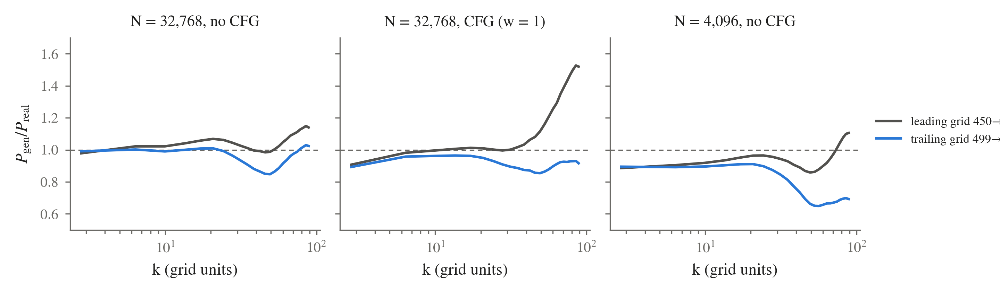

,lead_k3,lead_highk6,trail_k3,trail_highk6,lead_bias_W,lead_cov68,trail_bias_W,trail_cov68
arm,,,,,,,,
a,0.979,1.127,0.991,1.007,0.052,21,-0.125,25
b,0.908,1.472,0.893,0.926,-0.046,24,-0.152,25
c,0.886,1.052,0.895,0.687,-0.160,24,-0.252,20


In [16]:
display(Image(str(NK / 'grid_pk.png'), width=1000))
display(pd.read_csv(NK / 'grid_test_summary.csv').drop(columns='run').set_index('arm').round(3))

## Open decisions
1. Run the fine-tune *without* augmentation at N = 1,024 (≈3.5 GPU-h) to separate augmentation from extra training.
2. Train the conditional models with D4 + translations from the start (prepared, ≈12 GPU-h per N).
3. Fix the criterion for choosing w before the next CFG comparison.
4. Camera-ready items for the ML4PS paper: bootstrap errors on coverage, generated-minus-real differences, field construction, higher-order statistics.